In [1]:
import pandas as pd                      # for working with tables
import numpy as np                       # for numbers and random values
import matplotlib.pyplot as plt          # for charts

from scipy.special import betaln         # needed for the Bayesian "marginal likelihood"
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, roc_auc_score, accuracy_score

print("Ready.")

Ready.


In [2]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

url = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"
data = pd.read_csv(url, header=None, names=column_names)

# 1 = attack of any kind, 0 = normal
data["attack"] = (data["label"] != "normal").astype(int)

print("Number of rows:", len(data))
print("Share of attacks:", round(data["attack"].mean() * 100, 1), "%")

Number of rows: 125973
Share of attacks: 46.5 %


In [3]:
# Lock away 30% of the data. It is only used for the final scoring.
train, test = train_test_split(data, test_size=0.3, random_state=42, stratify=data["attack"])

print("Training rows:", len(train))
print("Test rows    :", len(test))

Training rows: 88181
Test rows    : 37792


In [4]:
# THE CANDIDATE MODELS
# Each model is a different guess about WHICH signals reveal an intrusion.
# A model works like a lookup table: cut each chosen feature into a few bins,
# then every combination of bins (a "cell") gets its own attack probability.
#
# "inner" lists the cut points. Example: [0.2, 0.8] makes 3 bins: below 0.2, 0.2 to 0.8, above 0.8.

candidate_models = {
    "errors_only": [("serror_rate", [0.2, 0.8])],
    "errors_service": [("serror_rate", [0.2, 0.8]), ("same_srv_rate", [0.3, 0.9])],
    "errors_service_volume": [("serror_rate", [0.2, 0.8]), ("same_srv_rate", [0.3, 0.9]),
                              ("src_bytes", [1, 200, 1000])],
    "volume": [("src_bytes", [1, 200, 1000]), ("dst_bytes", [1, 200, 1000])],
    "host_level": [("dst_host_srv_count", [10, 100, 255]), ("dst_host_serror_rate", [0.2, 0.8])],
}

def cell_of(df, parts):
    """Give every row the number of its cell (its combination of bins)."""
    cell = np.zeros(len(df), dtype=int)
    for column_name, inner in parts:
        cell = cell * (len(inner) + 1) + np.digitize(df[column_name].values, inner)
    return cell

overview = pd.DataFrame({
    "features used": [", ".join(name for name, inner in parts) for parts in candidate_models.values()],
    "number of cells": [int(np.prod([len(inner) + 1 for name, inner in parts])) for parts in candidate_models.values()],
}, index=candidate_models.keys())
overview

,features used,number of cells
errors_only,serror_rate,3
errors_service,"serror_rate, same_srv_rate",9
errors_service_volume,"serror_rate, same_srv_rate, src_bytes",36
volume,"src_bytes, dst_bytes",16
host_level,"dst_host_srv_count, dst_host_serror_rate",12


In [5]:
# LEARNING = COUNTING (the same idea as Unit 1).
# For every cell: how many connections landed in it, and how many of those were attacks?

MAX_CELLS = 100

def fit_counts(df, parts):
    cell = cell_of(df, parts)
    n = np.bincount(cell, minlength=MAX_CELLS)[:MAX_CELLS]                              # connections per cell
    k = np.bincount(cell, weights=df["attack"].values, minlength=MAX_CELLS)[:MAX_CELLS]  # attacks per cell
    return n, k

def predict_prob(df, parts, n, k):
    """Posterior mean of P(attack) in the cell: (attacks + 1) / (connections + 2).
    The +1 and +2 come from a flat Beta(1,1) prior: before seeing data, every probability is equally likely."""
    cell = cell_of(df, parts)
    return (k[cell] + 1) / (n[cell] + 2)

# Show what one model learned from ALL the training data
n_all, k_all = fit_counts(train, candidate_models["errors_service"])
rows = []
for serror_bin in range(3):
    for service_bin in range(3):
        c = serror_bin * 3 + service_bin
        rows.append({"serror_rate bin": ["low", "middle", "high"][serror_bin],
                     "same_srv_rate bin": ["low", "middle", "high"][service_bin],
                     "connections": int(n_all[c]), "attacks": int(k_all[c]),
                     "P(attack)": round((k_all[c] + 1) / (n_all[c] + 2), 3)})
pd.DataFrame(rows)

,serror_rate bin,same_srv_rate bin,connections,attacks,P(attack)
0,low,low,7756,6869,0.886
1,low,middle,1899,648,0.341
2,low,high,52896,8963,0.169
3,middle,low,249,232,0.928
4,middle,middle,88,64,0.722
5,middle,high,736,17,0.024
6,high,low,22551,22523,0.999
7,high,middle,1211,1211,0.999
8,high,high,795,514,0.646


In [6]:
# Labeled intrusion data is expensive: someone has to investigate every connection.
# So imagine we only have 100 labeled connections.

labeled = train.sample(n=100, random_state=3)

fits = {name: fit_counts(labeled, parts) for name, parts in candidate_models.items()}

print("Labeled connections:", len(labeled))
print("Of which attacks   :", int(labeled["attack"].sum()))

Labeled connections: 100
Of which attacks   : 46


In [7]:
# HOW MUCH SHOULD WE BELIEVE EACH MODEL?
# Bayes' rule applied to models:  P(model | data)  is proportional to  P(data | model) x P(model)
#
# P(data | model) is the "marginal likelihood". For our lookup tables it has an exact formula
# (no approximation): add up betaln(1 + attacks, 1 + normals) over all cells.
# A model with MANY cells has to spread its bets thinly, so it is punished automatically
# unless the data really needs those extra cells.

def log_marginal_likelihood(n, k):
    return np.sum(betaln(1 + k, 1 + n - k))

prior = {name: 1 / len(candidate_models) for name in candidate_models}     # no favourite to start with

def model_weights(fits):
    log_score = pd.Series({name: log_marginal_likelihood(*fits[name]) + np.log(prior[name]) for name in fits})
    weights = np.exp(log_score - log_score.max())       # subtract the max first so the numbers do not underflow
    return log_score, weights / weights.sum()

log_score, weights = model_weights(fits)

weight_table = pd.DataFrame({"log marginal likelihood": log_score.round(2), "weight": weights.round(3)})
print("Weights always add up to 1:", round(weights.sum(), 3))
weight_table

Weights always add up to 1: 1.0


,log marginal likelihood,weight
errors_only,-42.45,0.001
errors_service,-36.76,0.211
errors_service_volume,-36.24,0.353
volume,-36.08,0.414
host_level,-39.04,0.022


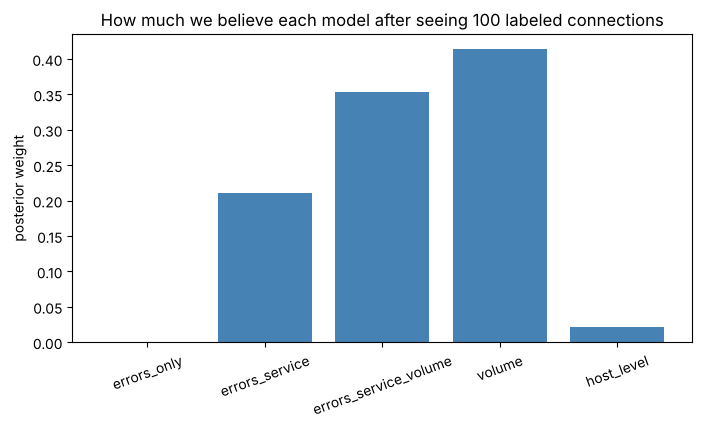

In [8]:
plt.figure(figsize=(8, 4))
plt.bar(weights.index, weights.values, color="steelblue")
plt.ylabel("posterior weight")
plt.title("How much we believe each model after seeing 100 labeled connections")
plt.xticks(rotation=20)
plt.show()

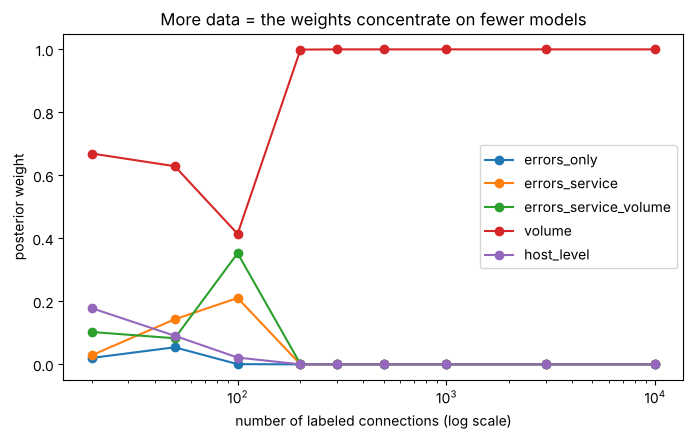

,errors_only,errors_service,errors_service_volume,volume,host_level
20,0.020,0.029,0.103,0.669,0.179
50,0.054,0.143,0.083,0.629,0.091
100,0.001,0.211,0.353,0.414,0.022
200,0.000,0.000,0.001,0.999,0.000
300,0.000,0.000,0.000,1.000,0.000
500,0.000,0.000,0.000,1.000,0.000
1000,0.000,0.000,0.000,1.000,0.000
3000,0.000,0.000,0.000,1.000,0.000
10000,0.000,0.000,0.000,1.000,0.000


In [9]:
# What happens to the weights as we get MORE labeled data?
sizes = [20, 50, 100, 200, 300, 500, 1000, 3000, 10000]
history = []

for size in sizes:
    subset = train.sample(n=size, random_state=3)
    subset_fits = {name: fit_counts(subset, parts) for name, parts in candidate_models.items()}
    history.append(model_weights(subset_fits)[1])

history = pd.DataFrame(history, index=sizes)

plt.figure(figsize=(8, 4.5))
for name in history.columns:
    plt.plot(history.index, history[name], marker="o", label=name)
plt.xscale("log")
plt.xlabel("number of labeled connections (log scale)")
plt.ylabel("posterior weight")
plt.title("More data = the weights concentrate on fewer models")
plt.legend()
plt.show()

history.round(3)

In [10]:
# Now score everything on the locked-away test set.
test_probabilities = {name: predict_prob(test, parts, *fits[name]) for name, parts in candidate_models.items()}

bma_probability = sum(weights[name] * test_probabilities[name] for name in candidate_models)   # Bayesian model averaging
equal_probability = np.mean(list(test_probabilities.values()), axis=0)                         # plain average, for comparison

def score_row(p):
    return {"log loss (lower is better)": round(log_loss(test["attack"], p), 4),
            "AUC (higher is better)": round(roc_auc_score(test["attack"], p), 4),
            "accuracy %": round(accuracy_score(test["attack"], p > 0.5) * 100, 1)}

results = {name: score_row(p) for name, p in test_probabilities.items()}
results["BMA (weighted average)"] = score_row(bma_probability)
results["equal-weight average"] = score_row(equal_probability)

comparison = pd.DataFrame(results).T
comparison

,log loss (lower is better),AUC (higher is better),accuracy %
errors_only,0.4465,0.7919,80.0
errors_service,0.3538,0.8763,86.8
errors_service_volume,0.3067,0.9258,87.3
volume,0.2633,0.9563,90.3
host_level,0.3301,0.9314,84.9
BMA (weighted average),0.2630,0.9667,87.1
equal-weight average,0.2969,0.9607,88.1


In [11]:
# One lucky or unlucky sample of 100 proves nothing. Repeat with 30 different random samples of 100.
# "Pick the winner" = use only the model with the highest weight and ignore the others.

winner_loss, bma_loss, equal_loss = [], [], []
winner_auc, bma_auc, equal_auc = [], [], []

for seed in range(30):
    small = train.sample(n=100, random_state=100 + seed)
    f = {name: fit_counts(small, parts) for name, parts in candidate_models.items()}
    w = model_weights(f)[1]
    p = {name: predict_prob(test, parts, *f[name]) for name, parts in candidate_models.items()}

    winner = p[w.idxmax()]
    bma = sum(w[name] * p[name] for name in p)
    equal = np.mean(list(p.values()), axis=0)

    winner_loss.append(log_loss(test["attack"], winner)); bma_loss.append(log_loss(test["attack"], bma)); equal_loss.append(log_loss(test["attack"], equal))
    winner_auc.append(roc_auc_score(test["attack"], winner)); bma_auc.append(roc_auc_score(test["attack"], bma)); equal_auc.append(roc_auc_score(test["attack"], equal))

repeat_table = pd.DataFrame({
    "average log loss": [np.mean(winner_loss), np.mean(bma_loss), np.mean(equal_loss)],
    "average AUC": [np.mean(winner_auc), np.mean(bma_auc), np.mean(equal_auc)],
}, index=["pick the winner", "BMA", "equal-weight average"]).round(4)

print("BMA had a lower log loss than pick-the-winner in",
      int(np.sum(np.array(bma_loss) < np.array(winner_loss))), "of 30 samples.")
print()
repeat_table

BMA had a lower log loss than pick-the-winner in 30 of 30 samples.



,average log loss,average AUC
pick the winner,0.2974,0.9376
BMA,0.2873,0.9645
equal-weight average,0.3072,0.9649


In [12]:
# With ALL 88,000 training rows the story changes.
full_fits = {name: fit_counts(train, parts) for name, parts in candidate_models.items()}
full_weights = model_weights(full_fits)[1]

full_probabilities = {name: predict_prob(test, parts, *full_fits[name]) for name, parts in candidate_models.items()}
full_bma = sum(full_weights[name] * full_probabilities[name] for name in candidate_models)

print("Weights with all the training data:")
print(full_weights.round(3))
print()
print("BMA log loss      :", round(log_loss(test["attack"], full_bma), 4))
print("Best single model :", round(min(log_loss(test["attack"], p) for p in full_probabilities.values()), 4))

Weights with all the training data:
errors_only              0.0
errors_service           0.0
errors_service_volume    0.0
volume                   1.0
host_level               0.0
dtype: float64

BMA log loss      : 0.2179
Best single model : 0.2179


In [13]:
rng = np.random.default_rng(0)

feature_defaults = {"serror_rate": 0.0, "same_srv_rate": 1.0, "src_bytes": 0, "dst_bytes": 0,
                    "dst_host_srv_count": 1, "dst_host_serror_rate": 0.0}

def bma_risk(draws=20000, quiet=False, **connection):
    """Attack probability for ONE connection, with an honest range, using the 100-label models."""
    row = pd.DataFrame([{**feature_defaults, **connection}])

    per_model = {}                      # each model's best guess, and the Beta distribution behind it
    samples = []
    counts = rng.multinomial(draws, weights.values)        # how many draws each model gets, in proportion to its weight
    for (name, parts), how_many in zip(candidate_models.items(), counts):
        n, k = fits[name]
        c = cell_of(row, parts)[0]
        a, b = 1 + k[c], 1 + n[c] - k[c]                   # Beta posterior for this model and this cell
        per_model[name] = a / (a + b)
        samples.append(rng.beta(a, b, size=how_many))
    samples = np.concatenate(samples)

    mean = samples.mean()
    low, high = np.percentile(samples, [5, 95])
    model_disagreement = np.sqrt(sum(weights[name] * (per_model[name] - mean) ** 2 for name in per_model))

    if not quiet:
        print("What each model says:")
        for name in per_model:
            print(f"   {name:<24} P(attack) = {per_model[name]:.2f}   (weight {weights[name]:.2f})")
        print()
        print(f"BMA attack probability: {mean:.2f}")
        print(f"90% range            : {low:.2f} to {high:.2f}")
        print(f"Models disagree by   : {model_disagreement:.2f}")
        if high - low > 0.4:
            print("Decision: UNSURE — the range is too wide. Send to an analyst.")
        elif mean >= 0.8:
            print("Decision: HIGH RISK — block or alert.")
        elif mean <= 0.2:
            print("Decision: LOW RISK — allow.")
        else:
            print("Decision: MEDIUM RISK — watch closely.")
    return samples


print("EXAMPLE 1 - ordinary short connection")
_ = bma_risk(serror_rate=0.0, same_srv_rate=1.0, src_bytes=230, dst_bytes=480,
             dst_host_srv_count=20, dst_host_serror_rate=0.0)

print()
print("EXAMPLE 2 - half-open connections everywhere (flood)")
_ = bma_risk(serror_rate=1.0, same_srv_rate=0.1, src_bytes=0, dst_bytes=0,
             dst_host_srv_count=15, dst_host_serror_rate=1.0)

print()
print("EXAMPLE 3 - borderline: middling errors, mixed services, moderate data")
borderline_samples = bma_risk(serror_rate=0.5, same_srv_rate=0.5, src_bytes=500, dst_bytes=2000,
                              dst_host_srv_count=120, dst_host_serror_rate=0.5)

EXAMPLE 1 - ordinary short connection
What each model says:
   errors_only              P(attack) = 0.21   (weight 0.00)
   errors_service           P(attack) = 0.14   (weight 0.21)
   errors_service_volume    P(attack) = 0.04   (weight 0.35)
   volume                   P(attack) = 0.09   (weight 0.41)
   host_level               P(attack) = 0.41   (weight 0.02)

BMA attack probability: 0.09
90% range            : 0.00 to 0.24
Models disagree by   : 0.06
Decision: LOW RISK — allow.

EXAMPLE 2 - half-open connections everywhere (flood)
What each model says:
   errors_only              P(attack) = 0.97   (weight 0.00)
   errors_service           P(attack) = 0.97   (weight 0.21)
   errors_service_volume    P(attack) = 0.97   (weight 0.35)
   volume                   P(attack) = 0.93   (weight 0.41)
   host_level               P(attack) = 0.95   (weight 0.02)

BMA attack probability: 0.95
90% range            : 0.87 to 1.00
Models disagree by   : 0.02
Decision: HIGH RISK — block or alert.


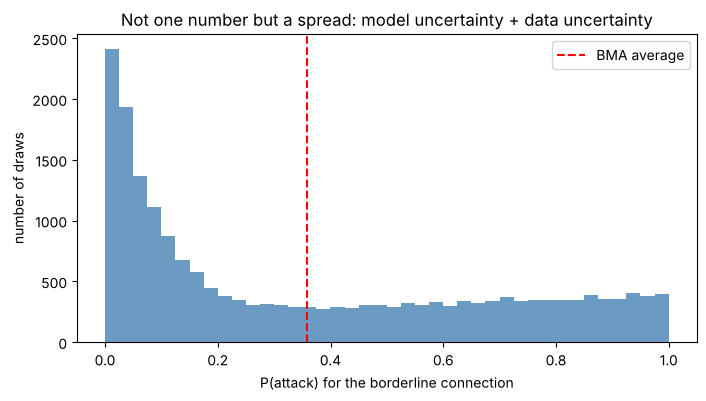

In [14]:
plt.figure(figsize=(8, 4))
plt.hist(borderline_samples, bins=40, color="steelblue", alpha=0.8)
plt.axvline(borderline_samples.mean(), color="red", linestyle="--", label="BMA average")
plt.xlabel("P(attack) for the borderline connection")
plt.ylabel("number of draws")
plt.title("Not one number but a spread: model uncertainty + data uncertainty")
plt.legend()
plt.show()

In [15]:
_ = bma_risk(serror_rate=0.0,
             same_srv_rate=0.4,
             src_bytes=0,
             dst_bytes=0,
             dst_host_srv_count=5,
             dst_host_serror_rate=0.0)

What each model says:
   errors_only              P(attack) = 0.21   (weight 0.00)
   errors_service           P(attack) = 0.50   (weight 0.21)
   errors_service_volume    P(attack) = 0.50   (weight 0.35)
   volume                   P(attack) = 0.93   (weight 0.41)
   host_level               P(attack) = 0.53   (weight 0.02)

BMA attack probability: 0.68
90% range            : 0.12 to 0.97
Models disagree by   : 0.21
Decision: UNSURE — the range is too wide. Send to an analyst.


In [16]:
weight_table.to_csv("unit5_model_weights.csv")
history.to_csv("unit5_weights_vs_data_size.csv")
comparison.to_csv("unit5_test_scores.csv")

print("Saved: unit5_model_weights.csv")
print("Saved: unit5_weights_vs_data_size.csv")
print("Saved: unit5_test_scores.csv")

Saved: unit5_model_weights.csv
Saved: unit5_weights_vs_data_size.csv
Saved: unit5_test_scores.csv


## What we found

1. **Five candidate models, five different guesses about what reveals an intrusion** (error rates, service mix, traffic volume, host-level counts, and a finer mix). Each one is a lookup table learned by counting. Because of that, the Bayesian "how much do we believe this model" score (the marginal likelihood) can be computed **exactly**, with no approximation.
2. **With only 100 labeled connections, belief is spread out:** `volume` about 41%, `errors_service_volume` about 35%, `errors_service` about 21%, and the other two close to 0%. No single model is clearly right yet, so averaging is meaningful.
3. **More data collapses the weights quickly.** At 200 labeled connections `volume` already holds about 99.9%, and with all 88,000 training rows it holds 100%. At that point BMA is just the best single model (log loss 0.2179 for both). BMA's advantage is a **small-data effect**.
4. **On 30 random sets of 100 labels, BMA gave better probabilities than picking the winner:** average log loss about 0.287 versus 0.297 (lower in 30 of 30 samples), and average AUC about 0.965 versus 0.938. The log loss gain is real but modest, roughly 3%. A plain equal-weight average reached about the same AUC (0.965) but a worse log loss (about 0.307).
5. **BMA improves the probabilities, not necessarily the yes/no decisions.** In the main 100-label run, accuracy at a 0.5 cut-off was 87.1% for BMA against 90.3% for `volume` alone.
6. **The real payoff is an honest range for each connection.** A flood gets about 0.95 with a 90% range of 0.87 to 1.00 and the models agree. A borderline connection gets about 0.36 with a range of 0.01 to 0.94, because the models disagree (`volume` says 0.07, `errors_service` says 0.67). That wide range is the signal to send it to an analyst instead of trusting one number.
7. **Limits to remember.** BMA only weighs the models you give it; if all five are wrong, it is confidently wrong among them. The weights also depend on the hand-picked bins and the flat prior. And the range assumes the labeled sample looks like the traffic you will see later.
8. Same NSL-KDD dataset as Units 1 to 4. Unit 1 introduced probability by counting; Unit 5 uses the same counting idea, but asks which counting model to trust.

## Reference

Dataset: NSL-KDD, Canadian Institute for Cybersecurity — https://www.unb.ca/cic/datasets/nsl.html